In [2]:
from pathlib import Path

import pandas as pd

In [3]:
data_path = Path("data/shap_xai_table.csv")
if not data_path.exists():
    data_path = Path("../data/shap_xai_table.csv")

df = pd.read_csv(data_path)

In [ ]:
# somma dei valori SHAP per ogni feature
df_somme = (
    df
    .sum(axis=0)
    .reset_index()
    .rename(columns={'index': 'feature', 0: 'Shap_importance'})
)


df_somme['feature'] = df_somme['feature'].str.replace('Shapley_', '', regex=False)

In [5]:
df_somme.sort_values(by='Shap_importance', ascending=False).head()

,feature,Shap_importance
15,CholesterolHDL,0.051768
7,SleepQuality,0.047506
16,CholesterolTriglycerides,0.001168
14,CholesterolLDL,0.000000
30,edu_none,0.000000


In [6]:
df_somme = df_somme[df_somme['Shap_importance'] != 0].reset_index(drop=True)


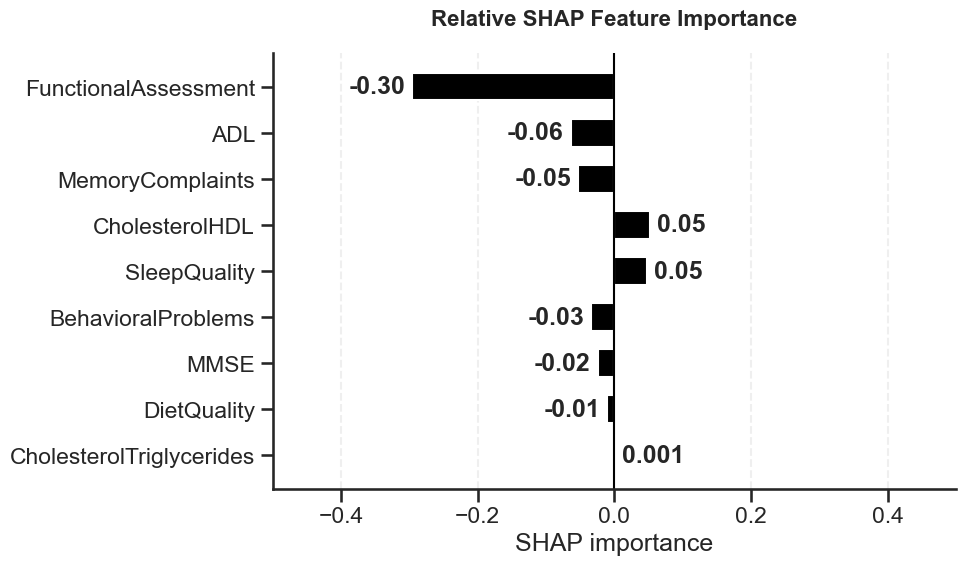

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

df_plot = df_somme.copy()

df_plot = df_plot[df_plot['Shap_importance'] != 0]

# sort per importanza (valori assoluti)
df_plot = df_plot.sort_values('Shap_importance', key=abs)

# colori
colors = df_plot['Shap_importance'].apply(
    lambda x: 'black'
)

sns.set_style("ticks")
sns.set_context("talk")



plt.figure(figsize=(10, 6))


bars = plt.barh(
    df_plot['feature'],
    df_plot['Shap_importance'],
    color=colors,
    height=0.6  
)

# Asse x al centro con range simmetrico
x_abs_max = np.max(np.abs(df_plot['Shap_importance']))
x_lim = 0.5

plt.axvline(0, color='black', linewidth=1.5)
plt.xlim(-x_lim, x_lim)

plt.xlabel('SHAP importance')
plt.ylabel('')
plt.title('Relative SHAP Feature Importance', fontweight='bold',fontsize=16, pad=20)       

# Griglie verticali
plt.grid(axis='x', alpha=0.3, linestyle='--')



# Etichette valori con formato dinamico
for bar in bars:
    width = bar.get_width()
    
    if width >= 0:
        x_pos = width + (x_lim * 0.02)
        ha = 'left'
    else:
        x_pos = width - (x_lim * 0.02)
        ha = 'right'
    
    # Formattazione dinamica
    abs_value = abs(width)
    
    if abs_value < 0.01:  # Se < 0.01% (es. 0.001, 0.005, etc.)
        # Conta le cifre decimali necessarie per mostrare il primo non-zero
        if abs_value == 0:
            n_decimals = 2  # Per 0.0
        else:
            # Calcola quante cifre servono dopo lo zero
            # Esempio: 0.001 → 3 decimali, 0.0005 → 4 decimali
            n_decimals = abs(int(np.floor(np.log10(abs_value)))) + 2
            n_decimals = min(n_decimals, 3)  # Massimo 4 decimali
    else:
        # Per valori >= 0.01%, usa 2 decimali
        n_decimals = 2
    
    # Formatta l'etichetta
    label = f'{width:.{n_decimals}f}'
    plt.text(x_pos, bar.get_y() + bar.get_height()/2, 
             label, ha=ha, va='center', fontweight='bold')

sns.despine()
plt.tight_layout()
plt.show()
